In [1]:
import numpy as np
import matplotlib.pyplot as plt

def correlation_regression(x, y):
    x = np.asarray(x, dtype=float)
    y = np.asarray(y, dtype=float)

    if x.ndim != 1 or y.ndim != 1:
        raise ValueError("x и y должны быть одномерными списками.")
    if len(x) != len(y) or len(x) < 2:
        raise ValueError("Нужно одинаковое количество значений x и y, минимум 2.")
    if not np.isfinite(x).all() or not np.isfinite(y).all():
        raise ValueError("Данные должны содержать только конечные числа.")
    if np.ptp(x) == 0 or np.ptp(y) == 0:
        raise ValueError("Для расчёта Пирсона значения x и y должны изменяться.")

    n = len(x)

    # Средние значения и стандартные отклонения
    x_mean = x.mean()
    y_mean = y.mean()
    sx = x.std(ddof=1)
    sy = y.std(ddof=1)

    # Коэффициент Пирсона через z-оценки
    zx = (x - x_mean) / sx
    zy = (y - y_mean) / sy
    r = np.sum(zx * zy) / (n - 1)

    # Коэффициент детерминации
    r_squared = r ** 2

    # Коэффициенты регрессии: ŷ = b0 + b1X
    b1 = np.sum((x - x_mean) * (y - y_mean)) / np.sum((x - x_mean) ** 2)
    b0 = y_mean - b1 * x_mean

    print(f"Коэффициент Пирсона r = {r:.4f}")
    print(f"Коэффициент детерминации R² = {r_squared:.4f}")
    print(f"R² в процентах = {r_squared:.2%}")
    print(f"Уравнение: ŷ = {b0:.4f} {b1:+.4f}X")

    # Две точки задают прямую на всём диапазоне x
    x_line = np.array([x.min(), x.max()])
    y_line = b0 + b1 * x_line

    plt.figure(figsize=(8, 5))
    plt.scatter(x, y, label="Исходные данные")
    plt.plot(x_line, y_line, color="red", label="Линейная регрессия")
    plt.xlabel("X")
    plt.ylabel("Y")
    plt.title("XY plot")
    plt.legend()
    plt.grid(alpha=0.3)
    plt.show()

    return {"r": r, "R2": r_squared, "b0": b0, "b1": b1}

Коэффициент Пирсона r = -0.9887
Коэффициент детерминации R² = 0.9776
R² в процентах = 97.76%
Уравнение: ŷ = 89.4000 -0.6971X


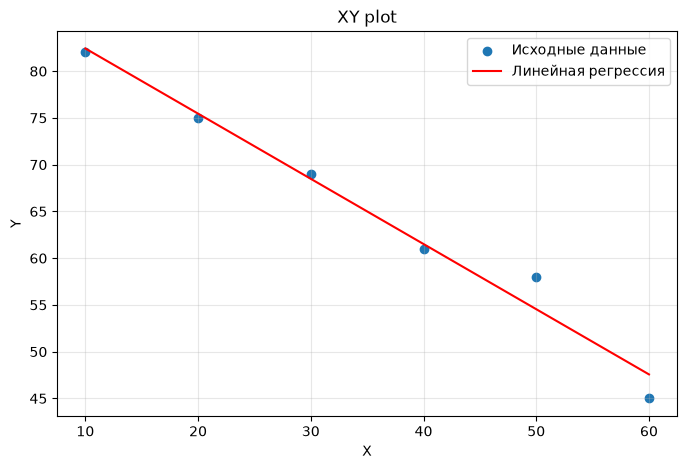

In [2]:
x = [10, 20, 30, 40, 50, 60]
y = [82, 75, 69, 61, 58, 45]

result = correlation_regression(x, y)

Коэффициент Пирсона r = 0.8783
Коэффициент детерминации R² = 0.7714
R² в процентах = 77.14%
Уравнение: ŷ = 1.8000 +0.7714X


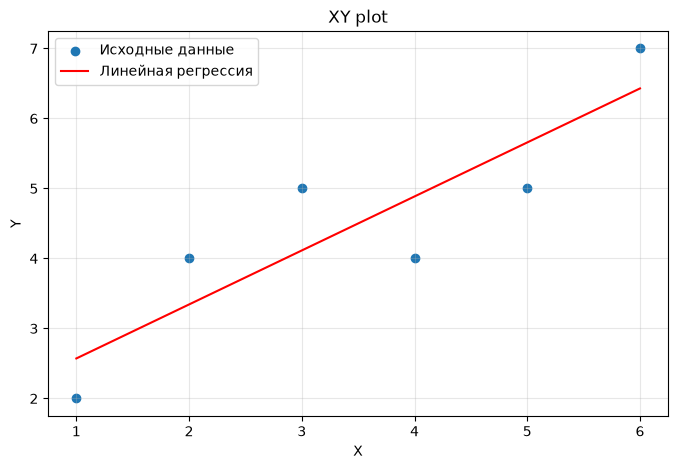

In [3]:
x = [1, 2, 3, 4, 5, 6]
y = [2, 4, 5, 4, 5, 7]

result = correlation_regression(x, y)